# Regional distributions of observed equity excess returns

Five countries, USD and EUR investor perspectives, and 144 matched months from October 2014 through September 2026. Observed excess return is the national equity index’s total return in the investor’s currency minus that currency’s cash rate. Returns are in monthly log percentage points. Run in the existing base kernel.

In [1]:
from hashlib import sha256
from io import BytesIO
import json
import os
from pathlib import Path

os.environ.setdefault("MPLCONFIGDIR", str(Path.cwd() / ".cache/matplotlib"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import gaussian_kde

snapshot = json.loads(Path("regional_dataset_inputs.json").read_text())
source = Path(snapshot["root"]) / "common"
months = pd.period_range(snapshot["common_start"], snapshot["common_end"], freq="M")
countries = {"HU": "Hungary", "PL": "Poland", "CZ": "Czechia", "RO": "Romania", "SE": "Sweden"}
currencies = ("USD", "EUR")

returns = {}
for code, country in countries.items():
    for currency in currencies:
        path = source / f"{code}_{currency}.csv"
        data = path.read_bytes()
        if sha256(data).hexdigest() != snapshot["files"][path.as_posix()]:
            raise ValueError(f"Frozen input changed: {path}")
        sample = pd.read_csv(BytesIO(data), float_precision="round_trip")
        values = 100 * sample["rx_local"].to_numpy()
        assert pd.PeriodIndex(sample["month"], freq="M").equals(months)
        assert len(values) == snapshot["common_months"] == 144 and np.isfinite(values).all()
        np.testing.assert_allclose(values, 100 * (sample["r_local"] - sample["rf"]), atol=1e-10)
        returns[country, currency] = values

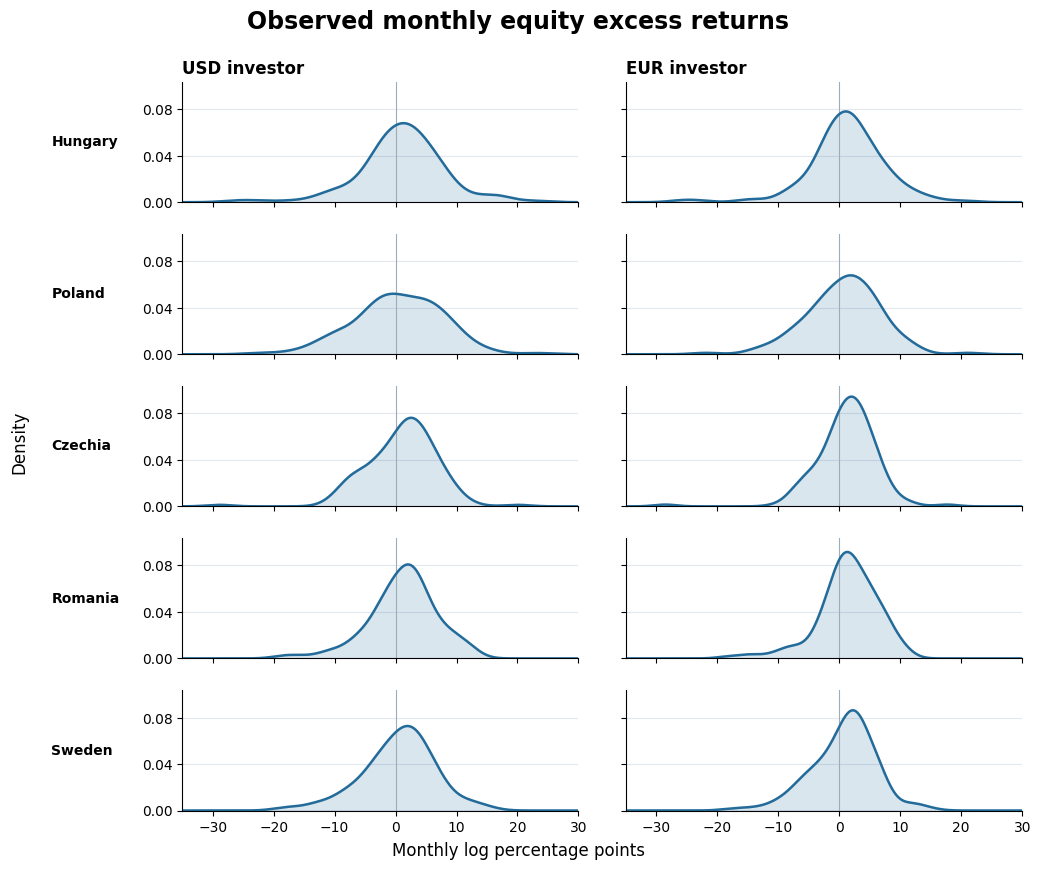

In [2]:
grid = np.linspace(-35, 30, 1500)
densities = {
    pair: gaussian_kde(values, bw_method="scott")(grid)
    for pair, values in returns.items()
}
upper = 1.1 * max(density.max() for density in densities.values())

fig, axes = plt.subplots(5, 2, figsize=(10.5, 9), sharex=True, sharey=True)
fig.subplots_adjust(left=0.18, right=0.98, bottom=0.09, top=0.90, wspace=0.12, hspace=0.26)
fig.suptitle("Observed monthly equity excess returns", fontsize=17, fontweight="bold")
fig.supxlabel("Monthly log percentage points", y=0.035)
fig.supylabel("Density", x=0.016)

for row, country in enumerate(countries.values()):
    for col, currency in enumerate(currencies):
        ax = axes[row, col]
        density = densities[country, currency]
        ax.axvline(0, color="#9eacb9", lw=0.8)
        ax.set_axisbelow(True)
        ax.grid(axis="y", color="#e1e8ef", lw=0.8)
        ax.fill_between(grid, density, color="#236b9a", alpha=0.17)
        ax.plot(grid, density, color="#236b9a", lw=1.8)
        ax.set(xlim=(grid[0], grid[-1]), ylim=(0, upper), yticks=(0, 0.04, 0.08))
        ax.spines[["right", "top"]].set_visible(False)
        if row == 0:
            ax.set_title(f"{currency} investor", loc="left", fontweight="bold")
        if col == 0:
            ax.text(-0.33, 0.5, country, transform=ax.transAxes,
                    ha="left", va="center", fontweight="bold")
plt.show()

**Summary statistics.** VaR and CVaR (expected shortfall) are reported as positive loss magnitudes. CVaR averages the worst 10% or 5% of months, with fractional weight at the cutoff. These figures use the raw returns. The KDE uses a Gaussian kernel with Scott bandwidth. “Below cash” is the share of months with negative excess returns. All figures except that share are in monthly log percentage points.

In [3]:
def expected_shortfall(losses, tail_fraction):
    # Each monthly loss starts with weight 1 / N. Include only the tail mass.
    worst_first = np.sort(losses)[::-1]
    tail_count = tail_fraction * len(losses)
    weights = np.clip(tail_count - np.arange(len(losses)), 0, 1)
    return weights @ worst_first / tail_count

rows = []
for (country, currency), values in returns.items():
    losses = -values
    rows.append({
        "Country": country,
        "Investor": currency,
        "Mean": values.mean(),
        "Median": np.median(values),
        "SD": values.std(ddof=1),
        "Worst": values.min(),
        "Best": values.max(),
        "Below cash (%)": 100 * np.mean(values < 0),
        "VaR 95%": np.quantile(losses, 0.95, method="inverted_cdf"),
        "CVaR 90%": expected_shortfall(losses, 0.10),
        "CVaR 95%": expected_shortfall(losses, 0.05),
    })

summary = pd.DataFrame(rows).set_index(["Country", "Investor"])
summary.round(2)

Mean  Median    SD  Worst   Best  Below cash (%)  VaR 95%  \
Country Investor                                                              
Hungary USD       1.10    1.34  6.92 -26.15  22.89           40.97    10.42   
        EUR       1.29    1.44  6.21 -25.80  20.56           37.50     7.47   
Poland  USD       0.47    0.21  7.19 -22.25  23.40           48.61    11.42   
        EUR       0.65    1.14  6.06 -21.90  21.08           40.28     9.03   
Czechia USD       1.00    1.71  5.75 -28.88  20.01           37.50     7.69   
        EUR       1.18    1.64  4.91 -28.53  17.68           34.03     6.77   
Romania USD       1.20    1.79  5.57 -18.53  12.58           34.72     8.45   
        EUR       1.38    1.53  4.94 -18.18  10.75           34.72     7.93   
Sweden  USD       0.51    0.95  5.95 -17.94  14.93           40.97    10.20   
        EUR       0.69    1.58  5.23 -17.59  14.67           37.50     8.25   

                  CVaR 90%  CVaR 95%  
Country Investor                      
Hungary USD          12.34     16.10  
        EUR          10.75     14.85  
Poland  USD          12.70     15.06  
        EUR          10.76     13.29  
Czechia USD           9.57     11.86  
        EUR           8.01     10.46  
Romania USD          10.00     13.13  
        EUR           9.10     12.22  
Sweden  USD          11.26     13.98  
        EUR           9.52     11.91